# The stocks: why the S&P 100, and what is in it

**DSAI4102 Applied Data Mining · Notebook 1 of 3** (run first: `stocks.ipynb` → `comovement_rules.ipynb` → `events.ipynb`)
Farid Abdul Rehman · Muzayyan Parkar · Mohamad Zain

This notebook explains which stocks we study and why, downloads their prices, checks the data, and explores how
the sectors behaved from 2016 to November 2026. It writes `data/prices.csv` and `data/stocks.csv`, which the other
two notebooks read.

## 1. What the S&P 100 is

* The **S&P 500** is the standard index of large US companies. The **S&P 100** is a subset of it, maintained by
  S&P Dow Jones Indices: roughly the 100 largest and most established S&P 500 companies, generally those with
  listed options. Index options on it trade under the ticker **OEX**, and the iShares ETF **OEF** tracks it.
* Like the S&P 500 it is weighted by free-float market value, so the biggest companies carry the most weight.
* Every company is classified into one of the **11 GICS sectors** (Global Industry Classification Standard):
  Information Technology, Communication Services, Consumer Discretionary, Consumer Staples, Health Care,
  Financials, Industrials, Energy, Utilities, Real Estate and Materials.
* The list changes over time. In March 2026, for example, MU, LRCX, AMAT and GEV were added as AI stocks grew,
  and PayPal, AIG, MetLife and Target were removed.

Sources: [S&P 100 index page](https://www.spglobal.com/spdji/en/indices/equity/sp-100),
[S&P DJI: Benchmarking blue chips, the S&P 100](https://www.spglobal.com/spdji/en/education/article/benchmarking-blue-chips-the-sp-100),
[Wikipedia: S&P 100](https://en.wikipedia.org/wiki/S%26P_100) (constituent list used below, read on 22 Nov 2026),
[24/7 Wall St, March 2026 changes](https://247wallst.com/investing/2026/03/06/mu-lrcx-amat-gev-all-added-to-the-sp-100-as-ai-stocks-gain-influence/).

## 2. Why these stocks

**Chosen by a fixed rule, not by us.** Our proposal used 40 hand-picked stocks in four groups, and the feedback
pointed out that the choice of stocks could decide the result. The S&P 100 is chosen by S&P with a published rule,
and it covers every sector, including banks, utilities, real estate and energy, which matter for the rate-news
tests in `events.ipynb`.

**The rules we apply to the list (stated before looking at any result):**
1. *Today's list* (22 Nov 2026). The index changes over time; a list from one past date would be just as much a
   choice, and today's list is the one anyone can check.
2. *One share class per company.* Alphabet appears twice (GOOG and GOOGL); we keep GOOGL, so 101 entries give
   100 companies.
3. *A stock enters when it has history.* Companies that listed after mid-2014 (for example Uber, Palantir,
   GE Vernova) are kept, but they only enter the analysis once they have a year of prices, because each stock's
   market sensitivity (beta) is estimated from the previous 252 trading days. Before that they simply have no moves.

**What this choice costs (survivorship bias).** Today's list holds the companies that *became* the largest. Some
were much smaller in 2016, especially the AI chip makers. Results about which stocks moved together are therefore
tilted towards today's winners. The event tests are hardly affected: event dates are fixed in advance and do not
depend on which companies grew. A fully neutral design would let companies enter and leave as the index changed;
that breaks rolling-window rule mining and is listed as a limitation.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

DATA = Path("data")
OUT_DIR = Path("outputs/stocks")
DATA.mkdir(exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

START, END = "2014-06-01", "2026-11-14"     # END is exclusive: the last day is Friday 13 Nov 2026
STUDY_START = "2016-01-01"                  # 2014-2015 is only used to estimate betas and volatility
MARKET = "SPY"                              # S&P 500 ETF, our stand-in for "the market"
MIN_HISTORY = 252 + 60                      # trading days a stock needs before it can make a "major move"

# S&P 100 constituents and GICS sectors, from Wikipedia's S&P 100 page on 22 Nov 2026 (GOOG dropped, see rule 2).
SP100 = """
AAPL|Apple|Information Technology
ABBV|AbbVie|Health Care
ABT|Abbott Laboratories|Health Care
ACN|Accenture|Information Technology
ADBE|Adobe|Information Technology
AMAT|Applied Materials|Information Technology
AMD|Advanced Micro Devices|Information Technology
AMGN|Amgen|Health Care
AMT|American Tower|Real Estate
AMZN|Amazon|Consumer Discretionary
ANET|Arista Networks|Information Technology
AVGO|Broadcom|Information Technology
AXP|American Express|Financials
BA|Boeing|Industrials
BAC|Bank of America|Financials
BKNG|Booking Holdings|Consumer Discretionary
BLK|BlackRock|Financials
BMY|Bristol Myers Squibb|Health Care
BNY|BNY Mellon|Financials
BRK-B|Berkshire Hathaway (Class B)|Financials
C|Citigroup|Financials
CAT|Caterpillar|Industrials
CMCSA|Comcast|Communication Services
COF|Capital One|Financials
COP|ConocoPhillips|Energy
COST|Costco|Consumer Staples
CRM|Salesforce|Information Technology
CSCO|Cisco|Information Technology
CVS|CVS Health|Health Care
CVX|Chevron|Energy
DE|Deere & Company|Industrials
DELL|Dell Technologies|Information Technology
DHR|Danaher|Health Care
DIS|Walt Disney|Communication Services
DUK|Duke Energy|Utilities
EMR|Emerson Electric|Industrials
FDX|FedEx|Industrials
GD|General Dynamics|Industrials
GE|GE Aerospace|Industrials
GEV|GE Vernova|Industrials
GILD|Gilead Sciences|Health Care
GM|General Motors|Consumer Discretionary
GOOGL|Alphabet (Class A)|Communication Services
GS|Goldman Sachs|Financials
HD|Home Depot|Consumer Discretionary
IBM|IBM|Information Technology
INTC|Intel|Information Technology
INTU|Intuit|Information Technology
ISRG|Intuitive Surgical|Health Care
JNJ|Johnson & Johnson|Health Care
JPM|JPMorgan Chase|Financials
KO|Coca-Cola|Consumer Staples
LIN|Linde|Materials
LLY|Eli Lilly|Health Care
LMT|Lockheed Martin|Industrials
LOW|Lowe's|Consumer Discretionary
LRCX|Lam Research|Information Technology
MA|Mastercard|Financials
MCD|McDonald's|Consumer Discretionary
MDLZ|Mondelez International|Consumer Staples
MDT|Medtronic|Health Care
META|Meta Platforms|Communication Services
MMM|3M|Industrials
MO|Altria|Consumer Staples
MRK|Merck & Co.|Health Care
MS|Morgan Stanley|Financials
MSFT|Microsoft|Information Technology
MU|Micron Technology|Information Technology
NEE|NextEra Energy|Utilities
NFLX|Netflix|Communication Services
NOW|ServiceNow|Information Technology
NVDA|Nvidia|Information Technology
ORCL|Oracle|Information Technology
PANW|Palo Alto Networks|Information Technology
PEP|PepsiCo|Consumer Staples
PFE|Pfizer|Health Care
PG|Procter & Gamble|Consumer Staples
PLTR|Palantir Technologies|Information Technology
PM|Philip Morris International|Consumer Staples
QCOM|Qualcomm|Information Technology
RTX|RTX Corporation|Industrials
SBUX|Starbucks|Consumer Discretionary
SCHW|Charles Schwab|Financials
SNDK|Sandisk|Information Technology
SO|Southern Company|Utilities
T|AT&T|Communication Services
TMO|Thermo Fisher Scientific|Health Care
TMUS|T-Mobile US|Communication Services
TSLA|Tesla|Consumer Discretionary
TXN|Texas Instruments|Information Technology
UBER|Uber|Industrials
UNH|UnitedHealth Group|Health Care
UNP|Union Pacific|Industrials
UPS|United Parcel Service|Industrials
USB|U.S. Bancorp|Financials
V|Visa|Financials
VZ|Verizon|Communication Services
WFC|Wells Fargo|Financials
WMT|Walmart|Consumer Staples
XOM|ExxonMobil|Energy
"""
# The semiconductor makers and equipment suppliers (GICS industry group "Semiconductors & Semiconductor
# Equipment"): the "AI enablers" whose co-movement with other stocks we follow in comovement_rules.ipynb.
SEMICONDUCTORS = ["NVDA", "AMD", "AVGO", "INTC", "MU", "QCOM", "TXN", "AMAT", "LRCX"]

stocks = pd.DataFrame([line.split("|") for line in SP100.strip().splitlines()], columns=["ticker", "name", "sector"])
stocks["semiconductor"] = stocks["ticker"].isin(SEMICONDUCTORS)
TICKERS = stocks["ticker"].tolist()
print(f"{len(stocks)} companies in {stocks['sector'].nunique()} sectors")

100 companies in 11 sectors


## 3. How many companies per sector

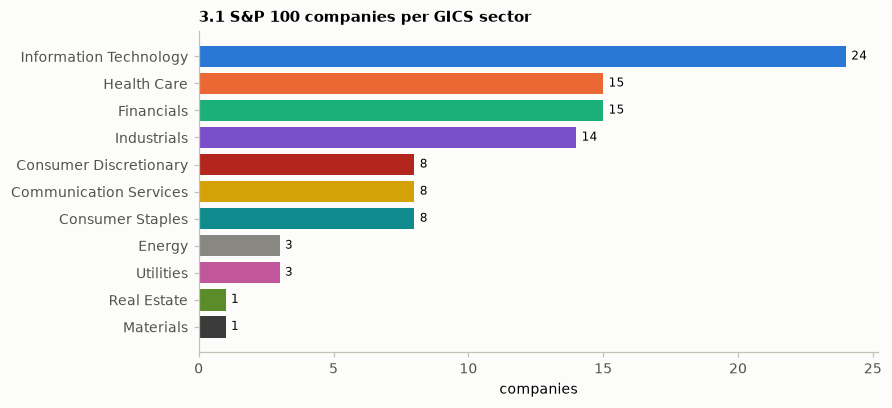

,tickers
sector,
Information Technology,"AAPL, ACN, ADBE, AMAT, AMD, ANET, AVGO, CRM, C..."
Health Care,"ABBV, ABT, AMGN, BMY, CVS, DHR, GILD, ISRG, JN..."
Financials,"AXP, BAC, BLK, BNY, BRK-B, C, COF, GS, JPM, MA..."
Industrials,"BA, CAT, DE, EMR, FDX, GD, GE, GEV, LMT, MMM, ..."
Consumer Discretionary,"AMZN, BKNG, GM, HD, LOW, MCD, SBUX, TSLA"
Communication Services,"CMCSA, DIS, GOOGL, META, NFLX, T, TMUS, VZ"
Consumer Staples,"COST, KO, MDLZ, MO, PEP, PG, PM, WMT"
Energy,"COP, CVX, XOM"
Utilities,"DUK, NEE, SO"


In [2]:
SECTOR_ORDER = stocks["sector"].value_counts().index.tolist()
SECTOR_COLORS = dict(zip(SECTOR_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#7a4fc9", "#b3261e", "#d4a106",
                                        "#0f8b8d", "#898781", "#c2569b", "#5b8c2a", "#3b3b3b"]))
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "xtick.color": "#c3c2b7", "ytick.color": "#c3c2b7", "xtick.labelcolor": "#52514e", "ytick.labelcolor": "#52514e",
    "grid.color": "#e1e0d9", "figure.dpi": 110, "savefig.dpi": 170, "savefig.bbox": "tight",
})


def save(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png")


counts = stocks["sector"].value_counts()
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
ax.barh(counts.index[::-1], counts.values[::-1], color=[SECTOR_COLORS[s] for s in counts.index[::-1]])
for y, v in enumerate(counts.values[::-1]):
    ax.text(v + 0.2, y, str(v), va="center", fontsize=8)
ax.set_xlabel("companies")
ax.set_title("3.1 S&P 100 companies per GICS sector")
save(fig, "3_1_companies_per_sector")
plt.show()
stocks.groupby("sector")["ticker"].apply(lambda s: ", ".join(s)).reindex(SECTOR_ORDER).to_frame("tickers")

## 4. Download the prices

Daily **adjusted** closing prices from Yahoo Finance with the open-source `yfinance` library (`auto_adjust=True`):
splits and dividends are folded into past prices, so Nvidia's 10-for-1 split in 2024 is not mistaken for a crash.
The first run downloads and saves `data/prices.csv`; later runs read that file, so the whole group works from the
same data. Delete the file to download again.

In [3]:
PRICES_PATH = DATA / "prices.csv"
if PRICES_PATH.exists():
    prices = pd.read_csv(PRICES_PATH, index_col=0, parse_dates=True)
    print(f"Read {PRICES_PATH}: {prices.shape[1]} columns")
else:
    import yfinance as yf
    raw = yf.download(TICKERS + [MARKET], start=START, end=END, auto_adjust=True, progress=False)
    prices = raw["Close"].dropna(how="all")
    prices.to_csv(PRICES_PATH)
    print(f"Downloaded and saved {PRICES_PATH}: {prices.shape}")

missing = [t for t in TICKERS + [MARKET] if t not in prices.columns or prices[t].isna().all()]
if missing:
    print("No prices for:", missing, "-> they are left out. Delete data/prices.csv and re-run to retry.")
stocks = stocks[~stocks["ticker"].isin(missing)].reset_index(drop=True)
TICKERS = stocks["ticker"].tolist()
prices = prices[TICKERS + [MARKET]].sort_index()
print(f"{prices.shape[0]} trading days, {prices.index[0].date()} to {prices.index[-1].date()}, {len(TICKERS)} stocks + {MARKET}")

Read data/prices.csv: 101 columns
3134 trading days, 2014-06-02 to 2026-11-13, 100 stocks + SPY


## 5. Data checks

* Missing values *inside* a stock's history (after its first price) would be a data problem.
* Missing values *before* a stock's first price are expected for companies that listed later; the table lists them
  with the date they enter the analysis (after `MIN_HISTORY` = 312 trading days of prices).
* Very large one-day moves are listed so they can be checked against the news.

In [4]:
first_day = prices.apply(pd.Series.first_valid_index)
gaps = {t: int(prices.loc[first_day[t]:, t].isna().sum()) for t in TICKERS}
print("Stocks with gaps inside their history:", {t: n for t, n in gaps.items() if n} or "none")

entry_day = {t: prices.index[min(prices.index.get_loc(first_day[t]) + MIN_HISTORY, len(prices) - 1)] for t in TICKERS}
stocks["first_price"] = stocks["ticker"].map(lambda t: first_day[t].date())
stocks["enters_analysis"] = stocks["ticker"].map(lambda t: max(entry_day[t], pd.Timestamp(STUDY_START)).date())
late = stocks[pd.to_datetime(stocks["enters_analysis"]) > pd.Timestamp(STUDY_START)]
print(f"{len(late)} companies enter after the study starts on {STUDY_START}:")
display(late[["ticker", "name", "sector", "first_price", "enters_analysis"]])

returns = prices.pct_change(fill_method=None)
big = returns[TICKERS].stack()
big = big[big.abs() > 0.25].sort_values()
print("One-day moves larger than 25% (check against news):")
big.rename("return").to_frame().assign(**{"return": lambda d: (d["return"] * 100).round(1)})

Stocks with gaps inside their history: none
5 companies enter after the study starts on 2016-01-01:


,ticker,name,sector,first_price,enters_analysis
31,DELL,Dell Technologies,Information Technology,2016-08-17,2017-11-10
39,GEV,GE Vernova,Industrials,2024-03-27,2025-06-26
77,PLTR,Palantir Technologies,Information Technology,2020-09-30,2021-12-27
83,SNDK,Sandisk,Information Technology,2025-02-13,2026-05-13
90,UBER,Uber,Industrials,2019-05-10,2020-08-05


One-day moves larger than 25% (check against news):


,,return
Date,,
2022-04-20,NFLX,-35.1
2026-10-30,INTC,-28.6
2024-02-21,PANW,-28.4
2026-10-29,NOW,-26.9
2022-02-03,META,-26.4
2024-08-02,INTC,-26.1
2026-07-14,IBM,-25.2
2020-03-24,COP,25.2
2021-01-22,PLTR,25.4


In [5]:
stocks.to_csv(DATA / "stocks.csv", index=False)
print(f"Saved {DATA / 'stocks.csv'} ({len(stocks)} companies) and {PRICES_PATH}")

Saved data/stocks.csv (100 companies) and data/prices.csv


## 6. How the sectors performed

**6.1 The whole period.** Growth of $1 invested at the start of 2016 in SPY and in an equal-weighted basket of each
sector's companies (a company joins its basket from its first price). Equal weighting shows the typical company,
not the few giants that dominate the index.

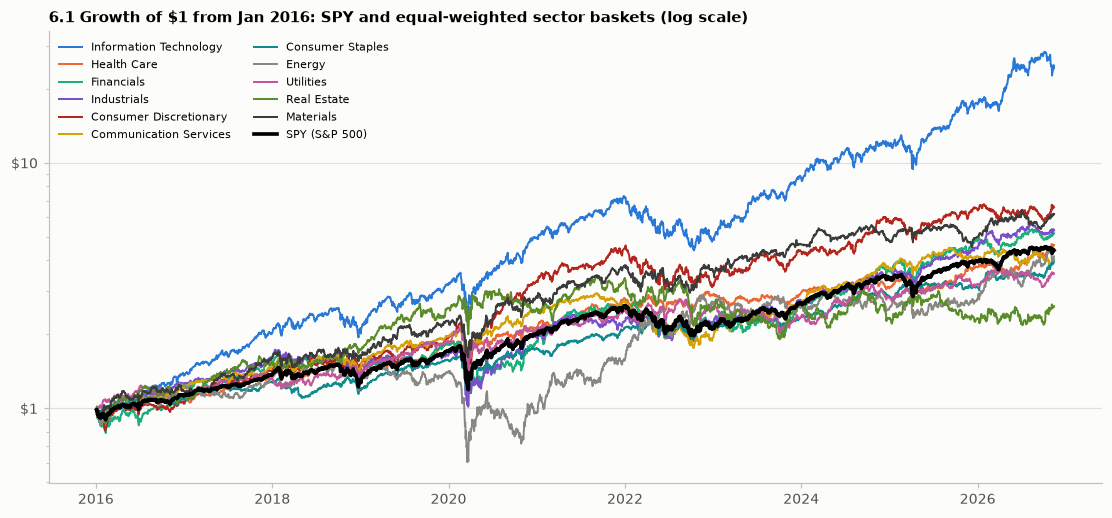

,companies,total return 2016-2026,annual volatility
Information Technology,24.0,23.33,0.27
Health Care,15.0,3.62,0.17
Financials,15.0,4.16,0.25
Industrials,14.0,4.30,0.21
Consumer Discretionary,8.0,5.58,0.22
Communication Services,8.0,3.03,0.19
Consumer Staples,8.0,2.97,0.15
Energy,3.0,3.15,0.30
Utilities,3.0,2.54,0.20
Real Estate,1.0,1.60,0.26


In [6]:
study = returns.loc[STUDY_START:]


def sector_return(df, members):
    return df[members].mean(axis=1, skipna=True)


sector_ret = pd.DataFrame({s: sector_return(study, stocks.loc[stocks["sector"] == s, "ticker"].tolist()) for s in SECTOR_ORDER})
growth = (1 + sector_ret.fillna(0)).cumprod()
spy_growth = (1 + study[MARKET].fillna(0)).cumprod()

fig, ax = plt.subplots(figsize=(10, 4.6), layout="constrained")
for s in SECTOR_ORDER:
    ax.plot(growth.index, growth[s], color=SECTOR_COLORS[s], lw=1.3, label=s)
ax.plot(spy_growth.index, spy_growth, color="black", lw=2.4, label="SPY (S&P 500)")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(lambda v, _: f"${v:,.0f}" if v >= 1 else f"${v:.1f}")
ax.grid(axis="y")
ax.legend(frameon=False, fontsize=7.5, ncol=2, loc="upper left")
ax.set_title("6.1 Growth of $1 from Jan 2016: SPY and equal-weighted sector baskets (log scale)")
save(fig, "6_1_growth_by_sector")
plt.show()

summary = pd.DataFrame({
    "companies": stocks["sector"].value_counts(),
    "total return 2016-2026": growth.iloc[-1] - 1,
    "annual volatility": sector_ret.std() * np.sqrt(252),
}).reindex(SECTOR_ORDER)
summary.loc["SPY"] = [np.nan, spy_growth.iloc[-1] - 1, study[MARKET].std() * np.sqrt(252)]
summary.round(2)

**6.2 Year by year.** The average cumulative return of each sector within each calendar year, with SPY in black.
This shows the regimes the event analysis has to live with: the 2020 crash and rebound, the 2022 rate-hike bear
market, and the 2023-2026 AI rally.

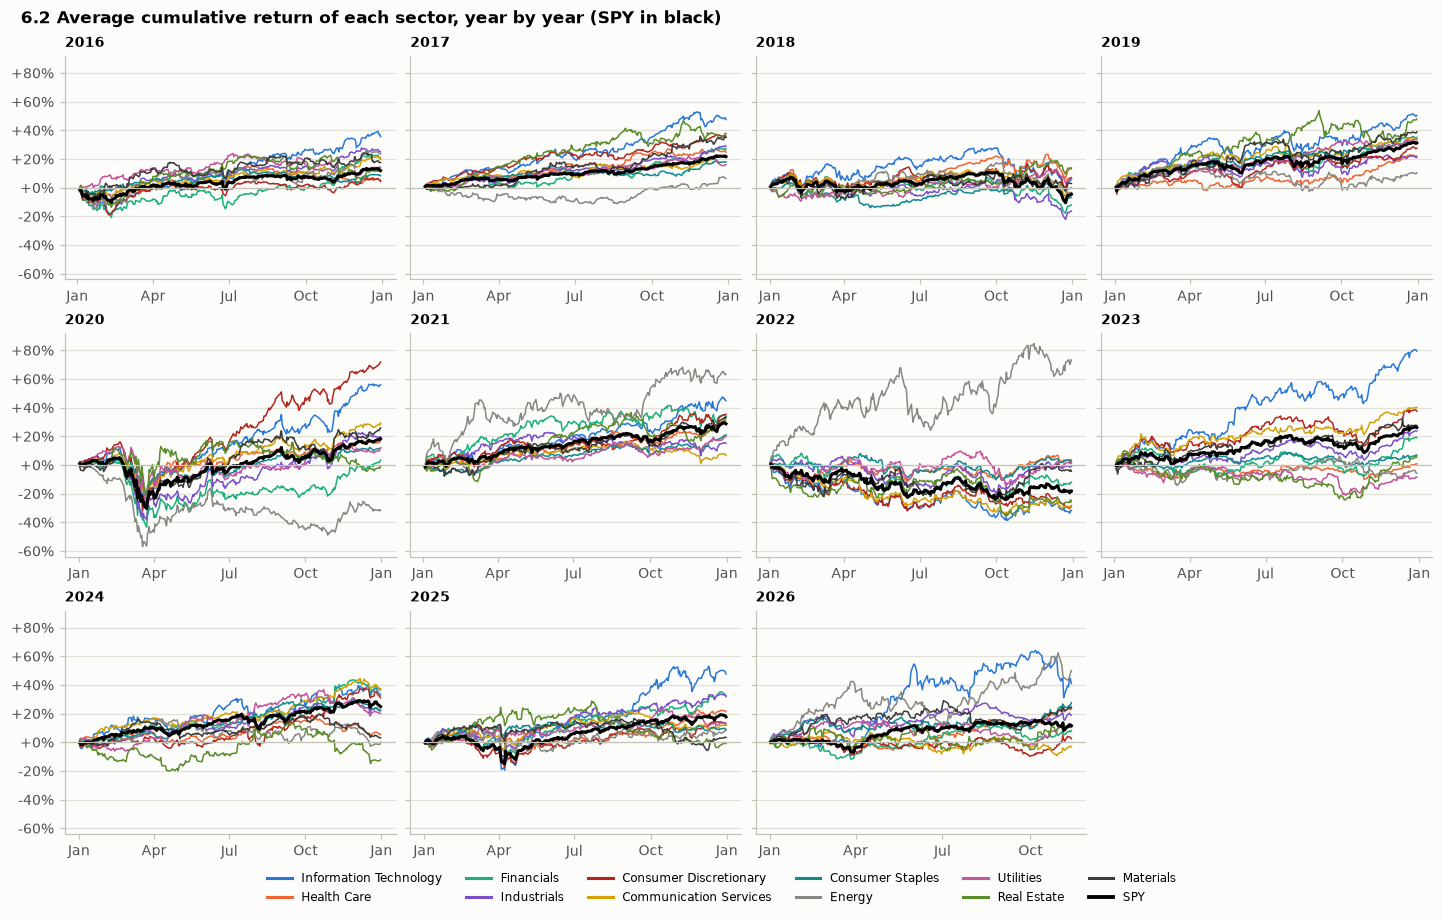

In [7]:
years = sorted(set(study.index.year))
ncol = 4
fig, axes = plt.subplots(int(np.ceil(len(years) / ncol)), ncol, figsize=(13, 2.6 * np.ceil(len(years) / ncol)),
                         sharey=True, layout="constrained")
for ax, y in zip(axes.flat, years):
    part = sector_ret[sector_ret.index.year == y]
    for s in SECTOR_ORDER:
        ax.plot(part.index, (1 + part[s].fillna(0)).cumprod() - 1, color=SECTOR_COLORS[s], lw=1)
    spy_part = study.loc[study.index.year == y, MARKET]
    ax.plot(spy_part.index, (1 + spy_part.fillna(0)).cumprod() - 1, color="black", lw=2)
    ax.axhline(0, color="#c3c2b7", lw=0.8)
    ax.set_title(str(y), fontsize=9)
    ax.xaxis.set_major_locator(mdates.MonthLocator([1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0%}")
    ax.grid(axis="y")
for ax in list(axes.flat)[len(years):]:
    ax.axis("off")
handles = [plt.Line2D([], [], color=SECTOR_COLORS[s], lw=2) for s in SECTOR_ORDER] + [plt.Line2D([], [], color="black", lw=2.5)]
fig.legend(handles, SECTOR_ORDER + ["SPY"], loc="lower center", ncol=6, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("6.2 Average cumulative return of each sector, year by year (SPY in black)", x=0.01, ha="left", fontweight="bold")
save(fig, "6_2_sector_returns_by_year")
plt.show()

**6.3 How much the stocks follow the market.** Each stock's beta (slope of its daily return on SPY's, 2016-2026)
and the average correlation between stocks inside and between sectors. Stocks in the same sector move together
more than stocks in different sectors, which is the co-movement the rules in `comovement_rules.ipynb` pick up,
and most stocks follow SPY strongly, which is why the market is removed before mining.

/var/folders/xp/s7v18px54kx6tkf_sxp6d9sh0000gn/T/ipykernel_97800/3308481428.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot([stocks.loc[stocks["sector"] == s, "beta"].dropna() for s in order], vert=False, tick_labels=order)


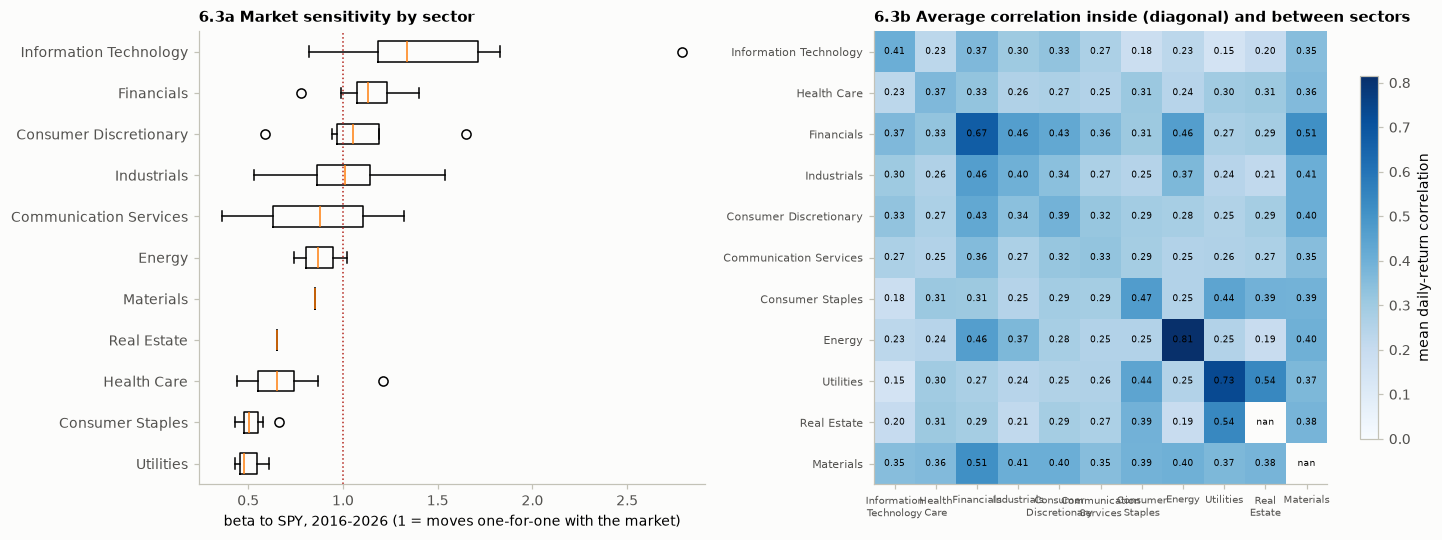

Mean correlation inside sectors 0.51, between sectors 0.31


In [8]:
beta = study[TICKERS].apply(lambda r: r.cov(study[MARKET]) / study[MARKET].var())
stocks["beta"] = stocks["ticker"].map(beta.round(2))
corr = study[TICKERS].corr(min_periods=252)
sec_of = stocks.set_index("ticker")["sector"]
block = pd.DataFrame(index=SECTOR_ORDER, columns=SECTOR_ORDER, dtype=float)
for a in SECTOR_ORDER:
    for b in SECTOR_ORDER:
        sub = corr.loc[sec_of.index[sec_of == a], sec_of.index[sec_of == b]].to_numpy()
        if a == b:
            sub = sub[~np.eye(len(sub), dtype=bool)]
        block.loc[a, b] = np.nanmean(sub)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained", gridspec_kw={"width_ratios": [1, 1.2]})
order = stocks.groupby("sector")["beta"].median().reindex(SECTOR_ORDER).sort_values().index
axes[0].boxplot([stocks.loc[stocks["sector"] == s, "beta"].dropna() for s in order], vert=False, tick_labels=order)
axes[0].axvline(1, color="#b3261e", ls=":", lw=1)
axes[0].set_xlabel("beta to SPY, 2016-2026 (1 = moves one-for-one with the market)")
axes[0].set_title("6.3a Market sensitivity by sector")
im = axes[1].imshow(block.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=float(np.nanmax(block.to_numpy(dtype=float))))
axes[1].set_xticks(range(len(SECTOR_ORDER)), [s.replace(" ", "\n", 1) for s in SECTOR_ORDER], fontsize=6.5)
axes[1].set_yticks(range(len(SECTOR_ORDER)), SECTOR_ORDER, fontsize=7)
for i in range(len(SECTOR_ORDER)):
    for j in range(len(SECTOR_ORDER)):
        axes[1].text(j, i, f"{block.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=axes[1], shrink=0.8, label="mean daily-return correlation")
axes[1].set_title("6.3b Average correlation inside (diagonal) and between sectors")
save(fig, "6_3_beta_and_sector_correlation")
plt.show()
print(f"Mean correlation inside sectors {np.nanmean(np.diag(block.to_numpy(dtype=float))):.2f}, "
      f"between sectors {np.nanmean(block.to_numpy(dtype=float)[~np.eye(len(block), dtype=bool)]):.2f}")
stocks.to_csv(DATA / "stocks.csv", index=False)